# Машинное обучение, ФКН ВШЭ

# Практическое задание 6. Бустинговое

## Общая информация

Дата выдачи: 08.12.2025

Мягкий дедлайн: 19.12.2025 23:59 MSK

Жёсткий дедлайн: 22.12.2025 23:59 MSK

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-06-Username.ipynb

Username — ваша фамилия на латинице

## О задании

В этом задании вам предстоит вручную запрограммировать один из самых мощных алгоритмов машинного обучения — бустинг. Однако с большой силой приходит и большая ответственность, поэтому придется научиться им пользоваться

In [3]:
from warnings import filterwarnings

import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set(style='darkgrid')
filterwarnings('ignore')

Мы будем работать с датасетом по предсказанию гендера. Никакие фичи мы придумывать не будем, но если вам интересно, в датасете имеется:

- region — регион, в котором проводили опрос
- age — возраст опрошенного
- year — год опроса
- race — этническая принадлежность
- sch — количество классов образования
- empstat — статус трудоустройства
- occ — код профессии
- ind — код индустрии, в которой человек работает
- ind annhrs — число часов работы в год
- hrwage — почасовая оплата
- icwage — суммарная оплата в год
- occupation — должность

Целевая метрика ROC-AUC, потому что мы непритязательны и это не фокус этой домашки



In [75]:
# !pip install pyarrow
# !pip install fastparquet

df = pd.read_parquet("boosting_dataset.pq")

X = df.drop("sex", axis=1)
y = df["sex"]

In [3]:
df.head()

,region,age,year,sex,race,sch,empstat,occ,ind,annhrs,hrwage,incwage,occupation
0,31,48,1981,1,1,12.0,12,634,628,240,4.233333,1016.0,transport
1,31,27,1981,1,2,9.0,10,901,777,1365,2.197802,3000.0,building
2,21,32,1981,1,1,16.0,10,343,859,1976,5.364372,10600.0,officeadmin
3,11,45,1981,1,1,12.0,10,75,839,2080,6.009615,12500.0,healthcare
4,11,31,1981,1,1,12.0,10,692,208,2080,6.206731,12910.0,production


In [11]:
df.describe()

,region,age,year,sex,race,sch,empstat,occ,ind,annhrs,hrwage,incwage
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04
mean,27.83140,41.711700,2002.631800,-0.015400,1.573900,13.517100,10.061600,2776.548800,4241.691900,2016.602700,19.109932,3.949619e+04
std,10.84684,10.449569,10.812138,0.999931,0.954898,2.785154,0.345568,2772.366892,3482.760252,603.212292,24.108353,4.419804e+04
min,11.00000,25.000000,1981.000000,-1.000000,1.000000,0.000000,10.000000,1.000000,10.000000,6.000000,0.957692,7.800000e+01
25%,21.00000,33.000000,1990.000000,-1.000000,1.000000,12.000000,10.000000,374.000000,762.000000,1920.000000,9.134615,1.650000e+04
50%,31.00000,41.000000,2007.000000,-1.000000,1.000000,13.000000,10.000000,1740.000000,4190.000000,2080.000000,14.423077,3.000000e+04
75%,41.00000,50.000000,2011.000000,1.000000,2.000000,16.000000,10.000000,4760.000000,7860.000000,2080.000000,23.629235,5.000000e+04
max,42.00000,64.000000,2013.000000,1.000000,4.000000,18.000000,12.000000,9750.000000,9590.000000,5148.000000,1394.230713,1.099999e+06


In [25]:
df.dtypes

region          int64
age             int64
year            int64
sex             int64
race            int64
sch           float64
empstat         int64
occ             int64
ind             int64
annhrs          int64
hrwage        float64
incwage       float64
occupation     object
dtype: object

Пока что мы времено выкинем колонку с должностью, но мы к ней обязательно вернемся

Разделим на обучающую, валидационную и тестовую выборки (оставьте `random_state=1337` для воспроизводимости).

In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X.drop("occupation", axis=1).values, y.values, test_size=0.2, random_state=1337
)
X_test, X_valid, y_test, y_valid = train_test_split(
    X_test, y_test, test_size=0.5, random_state=1337
)

X_train.shape, X_valid.shape, X_test.shape

((8000, 11), (1000, 11), (1000, 11))

---

## Задание 1. Базовый градиентный бустинг (4 балла)

Первая часть посвящена реализации собственного градиентного бустинга. Обращаем внимание, что пользоваться готовыми реализациями <font color='lightcoral'>**нельзя**</font>, если специально не оговорено. На все <font color='#b962c4'>**вопросы**</font> должен быть <font color='#b962c4'>**ответ**</font>. В заданиях, где нужно делать параметры, часто есть референсы из других библиотек. На случай, если объяснение из ноутбука непонятно, советуем обратиться к соответствующей документации и пощупать, как это делается там

Вам нужно дописать код в файлике `boosting.py`. Для вас уже подготовлен шаблон класса `Boosting`, вы можете менять его по своему усмотрению.

### Инструкции для функций:

#### `__init__`

Существующие параметры:
- `base_model_class` — класс базовой модели нашего бустинга
- `base_model_params` — словарь с гиперпараметрами для базовой модели
- `n_estimators` — какое количество базовых моделей нужно обучить
- `learning_rate` — темп обучения, должен быть из полуинтервала $(0, 1]$
- `random_state`— в роли рандом стейта
- `verbose` — для тех, кому не нравится загадочность, можно включить и увидеть, сколько еще ждать конца обучения

#### `fit`

В `fit` приходит выборка, на которой мы обучаем новые базовые модели

1. Сначала нам нужно сделать какую-то нулевую модель, сделать предсказания (в шаблоне это нулевая модель, соответственно предсказания это просто `np.zeros`).
2. После этого нужно обучить `n_estimators` базовых моделей (как и на что обучаются базовые модели смотрите в лекциях и семинарах).
3. После каждой обученной базовой модели мы должны обновить текущие предсказания, посчитать ошибку на выборке (используем `loss_fn` для этого) и найти новую оптимальную гамму

#### `partial_fit`

В `partial_fit` передаются данные `X: np.ndarray, y: np.ndarray` для одного шага бустинга: обучаем следующую базовую модель на антиградиенте и обновляем ансамбль.

#### `predict_proba`

В `predict_proba` приходит любая выборка, нужно предсказать вероятности для неё. Суммируем предсказания базовых моделей на этой выборке (не забываем про гаммы) и накидываем сигмоиду

In [9]:
%load_ext autoreload

In [10]:
%autoreload 2

from boosting import Boosting

### Проверка кода

In [7]:
boosting = Boosting(
    verbose=True,
    random_state=69, # не забывайте фиксировать, пожалуйста
)

boosting.fit(X_train, y_train)

assert len(boosting.models) == boosting.n_estimators
assert len(boosting.gammas) == boosting.n_estimators

assert boosting.predict_proba(X_test).shape == (X_test.shape[0], 2), "prediction shapes are incorrect"
assert np.array_equal(boosting.history["train_loss"], np.sort(boosting.history["train_loss"])[::-1]), "train loss is not decreasing"

assert boosting.predict_proba(X_test).shape == (X_test.shape[0], 2)

# здесь и далее работаем с метрикой ROC-AUC
print(f'Train ROC-AUC {boosting.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {boosting.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {boosting.score(X_test, y_test):.4f}')

100%|██████████| 20/20 [00:00<00:00, 26.64it/s]


Train ROC-AUC 1.0000
Valid ROC-AUC 0.7202
Test ROC-AUC 0.7514


Хорошим знаком будет ROC-AUC в районе 0.7, в зависимости от сида. Дефолтные параметры специально такие, чтобы прогнать модель быстро, поэтому не отчаивайтесь

---

## Задание 2. Имплементация гиперпараметров (3.5 балла | 3 бонус)

Бустинг, как метод агрегации, предлагает несколько вариантов регуляризации.

В этом пункте мы будем делать кучу самых разных гиперпараметров, каждый из них прекрасен по-своему, но полноценно их эффект получится ощутить лишь на этапе их перебора (кроме, пожалуй, `rsm`), поэтому делать третью часть до второй не рекомендуется

<font color='lightcoral'>**Важно!**</font> После добавления каждого параметра проверьте, как это повлияет на качество. Специально крутить параметры не нужно, но важно увидеть, что перформанс модели изменился, в худшую или в лучшую сторону. Для этого какие-то параметры нужны, пусть и от балды, <font color='lightcoral'>**гарантии, что дефолтные параметры подойдут, нет**</font>. Лучше всего это видно по графикам обучения <font color='lightcoral'>**на трейне и валидации**</font>, рекомендуется смотрить именно на них

### 2.1. Борьба с переобучением (1 балл)

Как известно, бустинги бывают склонны к переобучению. Чтобы этого не допустить, можно контролировать процесс обучения и проверять критерий останова на валидации прямо во время обучения. Реализуйте такую процедуру, не забудьте, что всю предобработку, что вы будете в дальнейшем делать для трейна, нужно будет повторить на валидации

Добавьте в вашу модель:
- `early_stopping_rounds: int | None = 0` — число раундов для критерия останова. Если качество ухудшается на протяжении всех раундов подряд, останавливаем обучение
- `eval_metric: str | None = None` — метрика, на которую смотрим, чтобы остановить обучение, может быть ключом из `model.history`
- `plot_history(self, keys: str | Iterable[str])` — метод, который строит график изменения метрики по ключам из `model.history`

И конкретно в метод `model.fit`:
- `eval_set: Tuple[np.ndarray] | None = None` — валидацонная выборка `X_valid: np.ndarray, y_valid: np.ndarray`, на которой будем проверять переобучение
- `use_best_model: bool = Fakse` — использовать лучшую модель, или нет. Если да, то отрезаем гаммы и модели вплоть до той, на которой остановились, минус `early_stopping_rounds`, т.е самой лучшей, после которой качество только падает

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td colspan="3" align="center"><code>early_stopping_rounds</code>, <code>eval_set</code></td>
</tr>
</table>

</div>

Продемонстируйте, что все работает

Тут я еще поигралась с реализованными ранее гиперпараметрами от переобучения

 12%|█▏        | 24/200 [00:00<00:06, 25.37it/s]


Early stopping at iteration 24


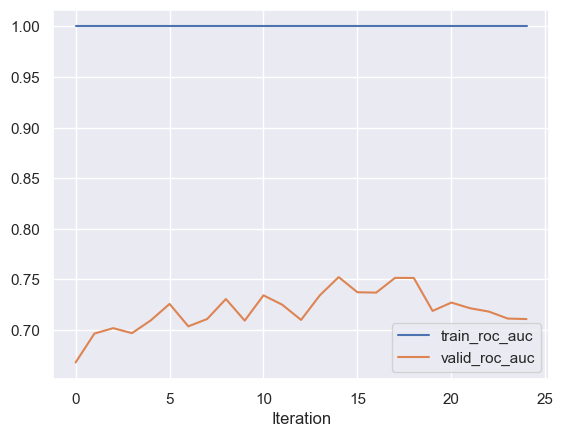

Train ROC-AUC 1.0000
Valid ROC-AUC 0.7524
Test ROC-AUC 0.7720


In [12]:
model = Boosting(
    n_estimators=200,
    learning_rate=0.1,
    early_stopping_rounds=10,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=True,
)

model.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid),
    use_best_model=True,
)

model.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {model.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {model.score(X_test, y_test):.4f}')


 48%|████▊     | 238/500 [00:05<00:05, 46.43it/s]


Early stopping at iteration 238


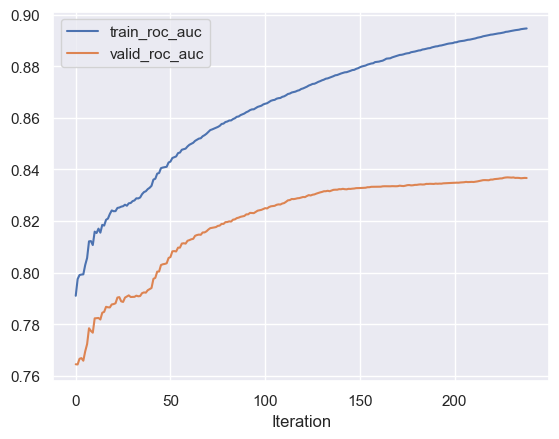

Train ROC-AUC 0.8934
Valid ROC-AUC 0.8369
Test ROC-AUC 0.8426


In [17]:
base_model_params = {
    "max_depth": 5,
    "min_samples_leaf": 10,
}

model = Boosting(
    base_model_params=base_model_params,
    n_estimators=500,
    learning_rate=0.1,
    early_stopping_rounds=10,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=True,
)

model.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid),
    use_best_model=True,
)

model.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {model.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {model.score(X_test, y_test):.4f}')


 76%|███████▌  | 381/500 [00:09<00:02, 41.75it/s]


Early stopping at iteration 381


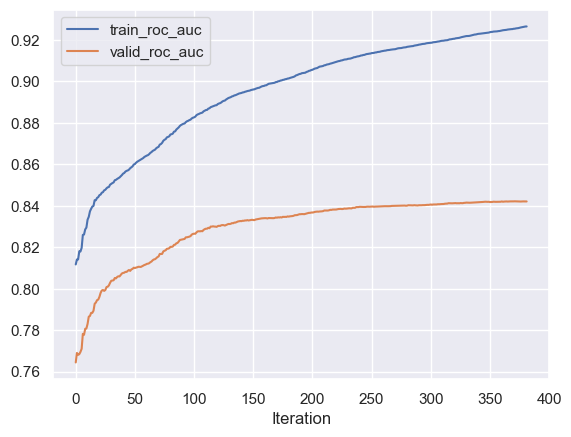

Train ROC-AUC 0.9254
Valid ROC-AUC 0.8422
Test ROC-AUC 0.8505


In [22]:
base_model_params = {
    "max_depth": 6,
    "min_samples_leaf": 14,
}

model = Boosting(
    base_model_params=base_model_params,
    n_estimators=500,
    learning_rate=0.1,
    early_stopping_rounds=10,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=True,
)

model.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid),
    use_best_model=True,
)

model.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {model.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {model.score(X_test, y_test):.4f}')


а это как без early stopping

100%|██████████| 500/500 [00:12<00:00, 40.76it/s]


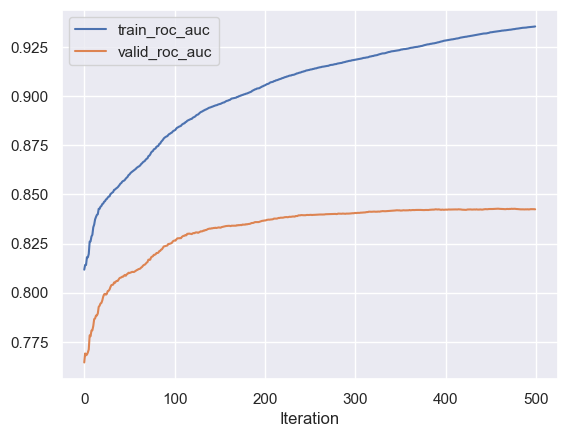

Train ROC-AUC 0.8117
Valid ROC-AUC 0.7644
Test ROC-AUC 0.7745


In [72]:
base_model_params = {
    "max_depth": 6,
    "min_samples_leaf": 14,
}

model = Boosting(
    base_model_params=base_model_params,
    n_estimators=500,
    learning_rate=0.1,
    random_state=69,
    verbose=True,
)

model.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid),
    use_best_model=True,
)

model.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {model.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {model.score(X_test, y_test):.4f}')


### Бонус. Бустинг линейных моделей (0.5 балла)

<font color='#b962c4'>**Вопрос:** что произойдет при ансамблировании линейных моделей? Имеет ли это смысл?</font>

<font color='#b962c4'>**Ответ:** ...</font>
Смысла в этом не очень много, так как при ансамблировании линейных моделей итоговая модель остается линейной по признакам, то есть ее прогноз это взвешенная сумма прогнозов базовых линейных моделей. Таким образом, ее выразительная способность не увеличивается с добавлением новых базовых моделей.
Бустинг в случае линейных моделей похож на итеративный градиентный спуск и может потенциально использоваться при online statistical learning.

Давайте убедимся. Обучите бустинг, где в качестве базовой модели будет линейная регрессия. Обязательно сохраните историю функции потерь и зафиксируйте время обучения. Можно взять уже готовый из <font color='#2f82d4'>**XGBoost**</font>, но будьте готовы разобраться с тем, как оттуда достать историю обучения

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>`XGBClassifier(booster="gblinear")</code></td>
<td align="center">-</td>
<td align="center">-</td>
</tr>
</table>

</div>

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚

Теперь возьмите `sklearn.linear_model.SGDClassifier` иобучите на тех же данных. Не забудьте понять, как вытащить оттуда историю функции потерь

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚

Покажите на одном графике изменение функции потерь для бустинга и SGD классификатора. Сравните следующие детали у бустинга и линейной модели:

- время обучения
- сходимость (как быстро, как стабильно и прочее)
- графики функции потерь на трейне и на валидации

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚

<font color='#b962c4'>**Вопрос:** Какой вывод вы можете сделать?</font>

<font color='#b962c4'>**Ответ:** ...</font>

### 2.2. Категории 2.0 (0.75 балла)

Пока что для простоты картины мы игнорировали категориальные признаки. <font color='#c4bf0a'>CatBoost</font> в частности предлагает один из самых эффективных и быстрых вариантов кодировки категорий, который мы попробуем повторить

> Основная идея в том, что важны не сами категории, а значения целевой переменной, которые имеют объекты этой категории. Каждый категориальный признак мы заменим средним значением целевой переменной по всем объектам этой же категории:

$$
g_j(x, X) = \frac{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)][y_i = +1]}{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)]}
$$


Добавьте в модель вот это:
- `cat_features: Iterable | None` — категориальные признаки для кодирования
- `_cat_fit(self, X: np.array, y: np.ndarray)` — внутренний метод для построения счетчиков
- `_cat_transform(self, X: np.ndarray)` — внутренний метод для применения счетчиков

Лмбо сделайте энкодер отдельным классом с аналогичными методами `fit` и `transform`, это даже лучше. Его нужно прогнать всего раз для каждой из выборок

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center">-</td>
<td align="center">-</td>
<td align="center"><code>cat_features</code></td>
</tr>
</table>

</div>

Закодируйте переменные, которые вы хотите считать категориальными, с помощью счётчиков (готовые реализации брать нельзя) и покажите эффект. Помните, что все должно быть векторизовано и красиво

In [76]:
# вернем occupation туда, где ему самое место, но это не единственная кат фича!

X = df.drop("sex", axis=1)
y = df["sex"]

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.2, random_state=1337
)
X_test, X_valid, y_test, y_valid = train_test_split(
    X_test, y_test, test_size=0.5, random_state=1337
)

X_train.shape, X_valid.shape, X_test.shape

((8000, 12), (1000, 12), (1000, 12))

In [34]:
cat_features = ["region", "race", "occupation", "empstat", "occ", "ind"]
all_features = list(X.columns)
all_features

['region',
 'age',
 'year',
 'race',
 'sch',
 'empstat',
 'occ',
 'ind',
 'annhrs',
 'hrwage',
 'incwage',
 'occupation']

In [24]:
from boosting import CatEncoder

encoder = CatEncoder(cat_features=cat_features)

encoder.fit(X_train, y_train, all_features)

X_train_enc = encoder.transform(X_train, all_features)
X_valid_enc = encoder.transform(X_valid, all_features)
X_test_enc = encoder.transform(X_test, all_features)

100%|██████████| 500/500 [00:11<00:00, 43.44it/s]


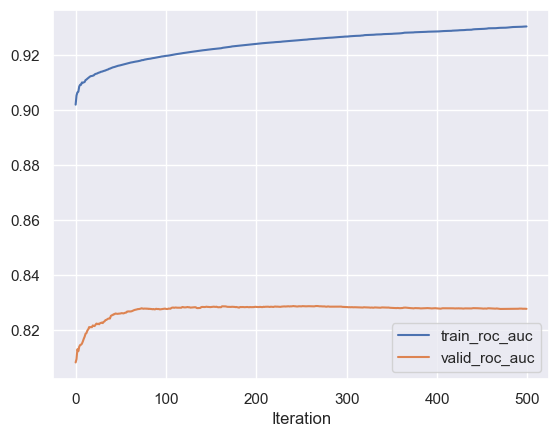

Train ROC-AUC 0.9019
Valid ROC-AUC 0.8082
Test ROC-AUC 0.8114


In [ ]:
base_model_params = {
    "max_depth": 4,
    "min_samples_leaf": 10,
}

model_cat = Boosting(
    base_model_params=base_model_params,
    n_estimators=500,
    learning_rate=0.1,
    random_state=69,
    verbose=True,
)

model_cat.fit(X_train_enc, y_train, eval_set=(X_valid_enc, y_valid), use_best_model=True)

model_cat.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model_cat.score(X_train_enc, y_train):.4f}')
print(f'Valid ROC-AUC {model_cat.score(X_valid_enc, y_valid):.4f}')
print(f'Test ROC-AUC {model_cat.score(X_test_enc, y_test):.4f}')

Видно, что качество значительно выросло, если сравнивать с моделью без регуляризации early stopping

 17%|█▋        | 83/500 [00:01<00:09, 43.70it/s]

Early stopping at iteration 83


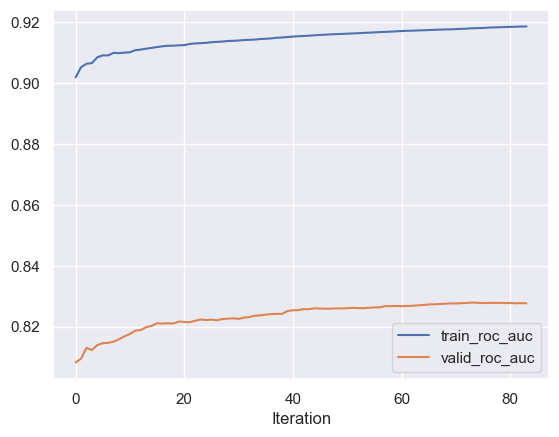

Train ROC-AUC 0.9180
Valid ROC-AUC 0.8279
Test ROC-AUC 0.8262


In [74]:
base_model_params = {
    "max_depth": 4,
    "min_samples_leaf": 10,
}

model_cat = Boosting(
    base_model_params=base_model_params,
    n_estimators=500,
    learning_rate=0.1,
    early_stopping_rounds=10,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=True,
)

model_cat.fit(X_train_enc, y_train, eval_set=(X_valid_enc, y_valid), use_best_model=True)

model_cat.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model_cat.score(X_train_enc, y_train):.4f}')
print(f'Valid ROC-AUC {model_cat.score(X_valid_enc, y_valid):.4f}')
print(f'Test ROC-AUC {model_cat.score(X_test_enc, y_test):.4f}')

Видно что для обучения понадобилось сильно меньше итераций, однако качество немного снизилось (возможно за счет обработки признаков, которых нет на val) по сравнению с моделью с early stopping из предыдущего пункта.

### Бонус. Категории 3.0 (0.5 балла)

Увы, закодированные признаки сами по себе являются классификаторами и, обучаясь на них, мы допускаем утечку целевой переменной в признаки, но с этим можно жить, в частности это одна из главных фишек <font color='#c4bf0a'>CatBoost</font>, была. Почитайте [статью](https://arxiv.org/pdf/1706.09516), она интересная

Реализуйте подсчет счетчиков так, чтобы кодировка категории была только по объектам. расположенным выше в датасете (например, если у нас выборка отсортирована по времени)

Методы добавлять не нужно, разве что очень хочется, предполагается, что это дефолтное поведение бустинга, на самом деле, если не нужен `OneHotEncoder `

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚

### 2.3. Бутстрап (0.75 балла)
Как известно, при обучении базовых алгоритмов в беггинге, используется бутстрапированная выборка. Звучит хайпово, почему бы не попробовать сделать то же самое в бустинге?

> Идея, которая за этим стоит проста - бустинги переобучаются, как черти. Бутстрап же может сделать процесс куда более робастным и быть одним из способов регуляризации, а заодно уменьшить время обучения, в случае бутстрапа Бернулли

Вам нужно реализовать параметры:
- `subsample: float = 1.0` — доля объектов, на которой будет обучаться базовая модель (какую часть составляет бутстрапная выборка от исходной обучающей). Соответствует бутстрапу типа `Bernoulli`. Каждый объект либо входит в подвыборку, либо нет
- `bagging_temperature: float = 1.0` — температура для генерации весов. Соответствует бутстрапу типа `Bayesian`. Каждому объекту присваивается вес $w$, который получается из температуры $t$, после чего объект, в количестве $w$, попадает в выборку. \
$w = (-\log(X))^t$, где $X \sim {U[0, 1]}$ \
Таким образом можно сделать симуляцию повторений, обобщив на непрерывный случай. Обычный бутстрап не умеет сэмплировать дробное число объектов, но можно сделать примерно то же самое, если размножить объект $w$ раз. Подумайте, как это корректно реализовать в бустинге
- `bootstrap_type: str | None = 'Bernoulli'` — тип бутстрапа

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>subsample</code>, -</td>
<td align="center"><code>subsample</code>, <code>bagging</code></td>
<td align="center"><code>subsample</code>, <code>bootstrap_type</code></td>
</tr>
</table>

</div>

<font color='#b962c4'>**Вопрос:** как бутстрап может помочь в обучении с точки зрения смещения, разброса и вообще?</font>

<font color='#b962c4'>**Ответ:** ... </font> 
Вообще бустрап мешает переобучению, поскольку обучение происходит не на целой выборке, что не позволяет базовой модели запоминать слишком сильно ошибки предыдущей. Этот метод увеличивает смещение как раз из-за того, что обучение на подвыборке происходит, однако это компенсирует пользой в уменьшении разброса. Каждая базовая модель видит немного разные данные, поэтому меньше переобучается на шумных остатках, и соответственно более стабильна.

 92%|█████████▏| 275/300 [00:05<00:00, 48.09it/s]


Early stopping at iteration 275
Bernoulli


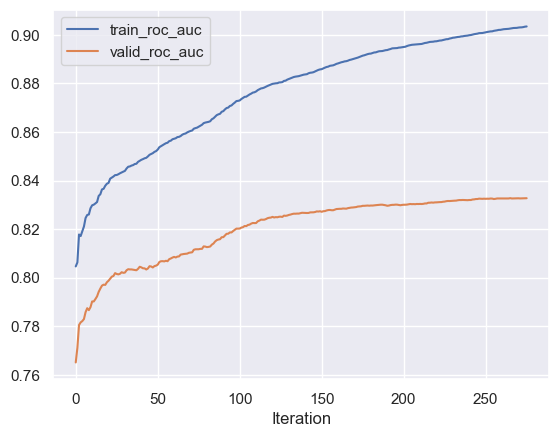

Train ROC-AUC 0.9026
Valid ROC-AUC 0.8327
Test ROC-AUC 0.8407


100%|██████████| 300/300 [00:05<00:00, 50.49it/s]

Bayesian


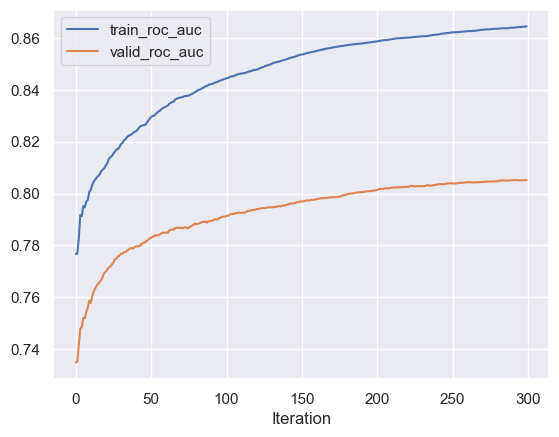

Train ROC-AUC 0.8640
Valid ROC-AUC 0.8052
Test ROC-AUC 0.8052


100%|██████████| 300/300 [00:07<00:00, 41.29it/s]

None


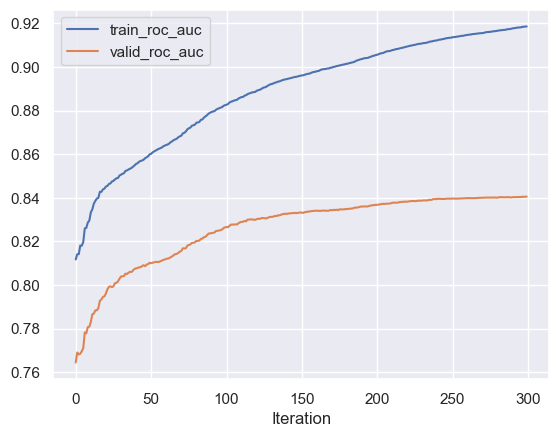

Train ROC-AUC 0.9186
Valid ROC-AUC 0.8405
Test ROC-AUC 0.8488


In [78]:
base_model_params = {
    "max_depth": 6,
    "min_samples_leaf": 14,
}

for b_type in ['Bernoulli', 'Bayesian', None]:
    model_bt = Boosting(
        base_model_params=base_model_params,
        n_estimators=300,
        learning_rate=0.1,
        random_state=69,
        verbose=True,
        early_stopping_rounds=10,
        eval_metric="valid_roc_auc",
        subsample=0.7,
        bagging_temperature=1.0,
        bootstrap_type=b_type
    )

    model_bt.fit(
        X_train,
        y_train,
        eval_set=(X_valid, y_valid),
        use_best_model=True,
    )
    print(f"{b_type}")
    model_bt.plot_history(["train_roc_auc", "valid_roc_auc"])

    print(f'Train ROC-AUC {model_bt.score(X_train, y_train):.4f}')
    print(f'Valid ROC-AUC {model_bt.score(X_valid, y_valid):.4f}')
    print(f'Test ROC-AUC {model_bt.score(X_test, y_test):.4f}')


Видно, что без бутстрап выборки результаты в целом лучше, тип Бернулли показывает более высокое качество.

Помимо выбора случайных объектов, есть идея выбирать случайное подмножество признаков, заложенная в Random Forest. Мотивация это делать точно та же самая, что и в бутстрапировании, за это будет отвечать параметр `rsm`

В библиотеках это реализовано так:

<div align="center">

| <font color="#2f82d4">XGBoost</font> | <font color="#41a657">LightGBM</font> | <font color='#d1cd3b'>CatBoost</font> |
| :---: | :---: | :---: |
| `colsample_bytree`| `colsample_bytree`| `rsm`|

</div>

Нужно добавить параметр:
- `rsm: float = 1.0` — доля признаков, участвующих в обучении модели. Каждый признак либо входит, либо не входит в пул, на котором обучается базовый алгоритм, по аналогии с бутстрапом Бернулли

  9%|▊         | 26/300 [00:00<00:04, 66.12it/s]


Early stopping at iteration 26
Bernoulli


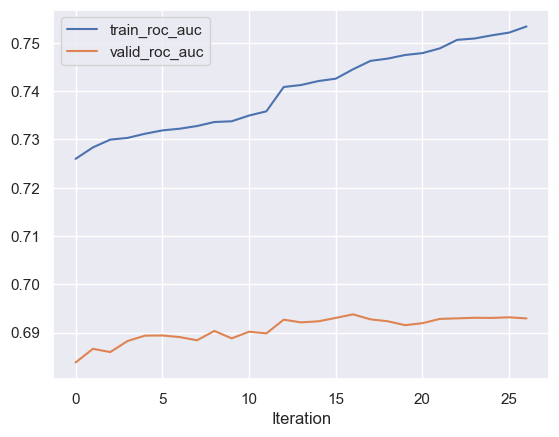

Train ROC-AUC 0.7445
Valid ROC-AUC 0.6938
Test ROC-AUC 0.7171


 85%|████████▌ | 255/300 [00:03<00:00, 65.52it/s]


Early stopping at iteration 255
Bayesian


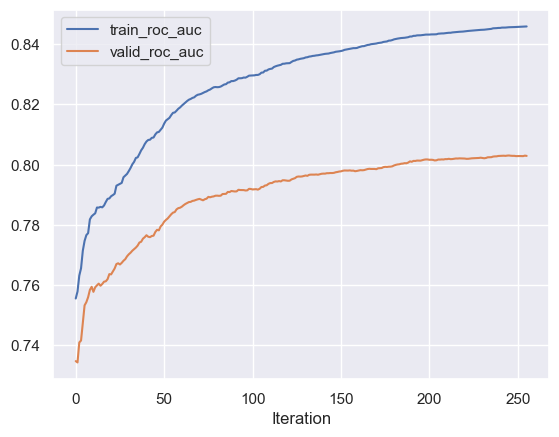

Train ROC-AUC 0.8456
Valid ROC-AUC 0.8031
Test ROC-AUC 0.8001


 59%|█████▉    | 178/300 [00:03<00:02, 56.63it/s]


Early stopping at iteration 178
None


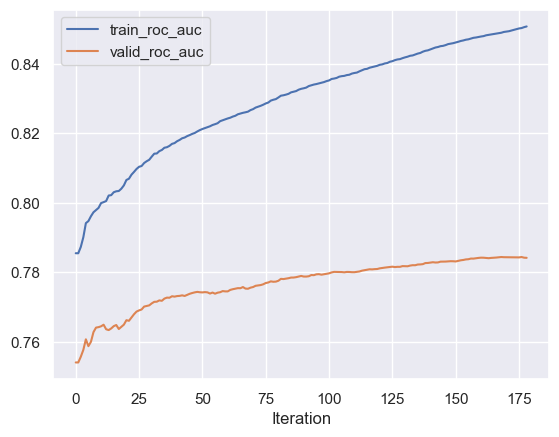

Train ROC-AUC 0.8489
Valid ROC-AUC 0.7844
Test ROC-AUC 0.7677


In [7]:
base_model_params = {
    "max_depth": 6,
    "min_samples_leaf": 14,
}

for b_type in ['Bernoulli', 'Bayesian', None]:
    model_bt = Boosting(
        base_model_params=base_model_params,
        n_estimators=300,
        learning_rate=0.1,
        random_state=69,
        verbose=True,
        early_stopping_rounds=10,
        eval_metric="valid_roc_auc",
        subsample=0.7,
        bagging_temperature=1.0,
        bootstrap_type=b_type,
        rsm=0.6
    )

    model_bt.fit(
        X_train,
        y_train,
        eval_set=(X_valid, y_valid),
        use_best_model=True,
    )
    print(f"{b_type}")
    model_bt.plot_history(["train_roc_auc", "valid_roc_auc"])

    print(f'Train ROC-AUC {model_bt.score(X_train, y_train):.4f}')
    print(f'Valid ROC-AUC {model_bt.score(X_valid, y_valid):.4f}')
    print(f'Test ROC-AUC {model_bt.score(X_test, y_test):.4f}')


Качество снизилось, но обучение ускорилось

### Бонус. GOSS (0.5 балла)

Заметим, что во время обучения не все объекты одинаково важны. Один из вариантов это исправить — ввести какие-то веса на объекты, однако можно пойти чуть хитрее. В <font color='#53c96c'>**LightGBM**</font> придумали подход [Gradient-based One-side Sampling](https://www.microsoft.com/en-us/research/wp-content/uploads/2017/11/lightgbm.pdf)

> Давайте оценивать важность объектов в отдельный момент обучения нового дерева. Будем считать, какой антиградиент привносит каждый объект. Далее разобъем градиенты на 2 группы. Объекты с большими (по модулю) градиентами берутся все, с маленькими — только часть, по аналогии с бутстрапом. И не забываем домножить на фактор, чтобы учесть выкинутые объекты. Подробнее в статье

Параметры, которые нужно сделать:

- `goss: bool = False` — GOSS бустинг или нет
- `goss_k: float = 0.2` — доля объектов, градиенты которых будем считать большими. Все остальное — маленькими
- `subsample: float = 0.3` — параметры сэмплинга Бернулли для маленьких градиентов из пункта 2.3

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center">-</td>
<td align="center"><code>bagging='goss'</code></td>
<td align="center"><code>bootstrap_type='MVS'</code></td>
</tr>
</table>

</div>

Сделайте и посмотрите

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚

### 2.4. Бинаризация (0.5 балла)

Вместо того, чтобы выкидывать признаки, можно попробовать проредить их множество значений, применив бинаризацию. В идеале это стоит делать с датасетом до обучения модели, но не обязательно, можно, например, на этапе `fit`, а в `partial_fit` приходит уже квантизованный датасет.

> Зачем это? Да все очень просто! Квантизованные данные весят гораздо меньше, знчаений в них куда как меньше, а значит, наше обучение пойдет гораздо быстрее, к тому же все снова станет устойчивее. Беда лишь в новых данных, которые могут оказаться вне бина, но великие силы избавили нас от этих проблем в нашем датасете. Фактически мотивация вновь та же, что у бутстрапа

Нужно добавить параметры:
- `quantization_type: str | None = None` — тип квантизации, если она есть
- `nbins: int = 255` — число бинов для квантизации. Игнорируем, если тип квантизации не указан

Либо сделать квантизатор отдельным классом, где в `fit` запоминаются пороги, а в `transform` преобразуются фичи

Рассмотрим варианта `quantization_type`:

- `'uniform'` — значения признака $[\min f_i, \max f_i]$ отображаются в `nbins` отрезков одинаковой длины, которые полностью покрывают интервал
- `'quantile'` — тот же самый отрезок сортируется и бьется на `nbins` квантилей от 0 до 1

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>tree_method</code></td>
<td align="center"><code>max_bin</code></td>
<td align="center"><code>quantize(...)</code></td>
</tr>
</table>

</div>

Разницу между ними вы можете увидеть на картинке, где квантизуется гауссиана

<img src="https://i.postimg.cc/gJ2SJgpN/image-2025-11-29-201502496.png">

Реализуйте их, примените их к числовым признакам, и покажите, что все работает четко

In [39]:
from boosting import Quantize

num_features = [
    i for i, f in enumerate(all_features)
    if f not in cat_features
]

quantizer = Quantize(
    quantization_type="quantile",
    nbins=255
)

quantizer.fit(X_train, num_features)

X_train_q = quantizer.transform(X_train)
X_valid_q = quantizer.transform(X_valid)
X_test_q  = quantizer.transform(X_test)

 82%|████████▏ | 408/500 [00:09<00:02, 43.90it/s]

Early stopping at iteration 408


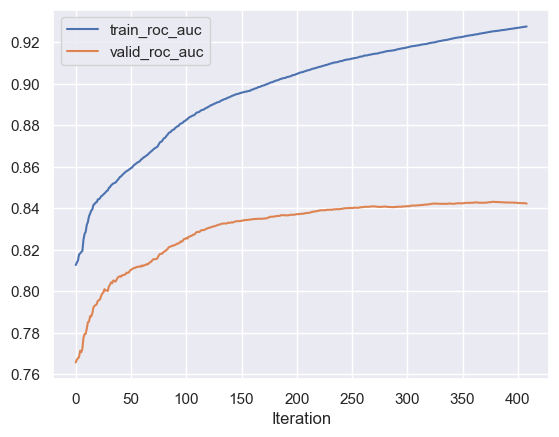

Train ROC-AUC 0.9252
Valid ROC-AUC 0.8431
Test ROC-AUC 0.8503


In [40]:
base_model_params = {
    "max_depth": 6,
    "min_samples_leaf": 14,
}

model = Boosting(
    base_model_params=base_model_params,
    n_estimators=500,
    learning_rate=0.1,
    early_stopping_rounds=30,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=True,
)

model.fit(
    X_train_q,
    y_train,
    eval_set=(X_valid_q, y_valid),
    use_best_model=True,
)

model.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model.score(X_train_q, y_train):.4f}')
print(f'Valid ROC-AUC {model.score(X_valid_q, y_valid):.4f}')
print(f'Test ROC-AUC {model.score(X_test_q, y_test):.4f}')


In [29]:
from boosting import Quantize

num_features = [
    i for i, f in enumerate(all_features)
    if f not in cat_features
]

quantizer = Quantize(
    quantization_type="uniform",
    nbins=255
)

quantizer.fit(X_train, num_features)

X_train_u = quantizer.transform(X_train)
X_valid_u = quantizer.transform(X_valid)
X_test_u  = quantizer.transform(X_test)

 75%|███████▍  | 373/500 [00:08<00:02, 46.07it/s]


Early stopping at iteration 373


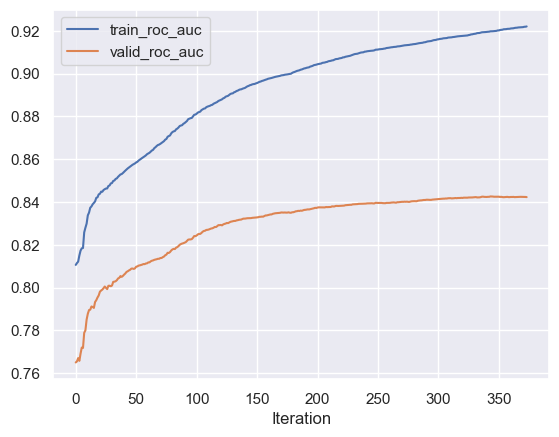

Train ROC-AUC 0.9198
Valid ROC-AUC 0.8426
Test ROC-AUC 0.8528


In [20]:
base_model_params = {
    "max_depth": 6,
    "min_samples_leaf": 14,
}

model = Boosting(
    base_model_params=base_model_params,
    n_estimators=500,
    learning_rate=0.1,
    early_stopping_rounds=30,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=True,
)

model.fit(
    X_train_u,
    y_train,
    eval_set=(X_valid_u, y_valid),
    use_best_model=True,
)

model.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model.score(X_train_u, y_train):.4f}')
print(f'Valid ROC-AUC {model.score(X_valid_u, y_valid):.4f}')
print(f'Test ROC-AUC {model.score(X_test_u, y_test):.4f}')


<font color='#b962c4'>**Вопрос**: как квантизация поможет в обработке выбросов и нанов?</font>

<font color='#b962c4'>**Ответ**: ... </font> С квантизацией выбросы объединяются в крайние бины, что снижает их влияние на обучение базовой модели (рассматривается не как конкретные экстремальные числовые значения, а как метка крайнего бина или редкая категория). Все наны также объединяются в отдельный бин и по сути становятся уникальным признаком для модели. В итоге модель становится более устойчивой.

<font color='#b962c4'>**Вопрос**: можно ли просто заполнить наны каким-то числом? Имеет ли значение, что это за число (-1, -100, -1e32)?</font>

<font color='#b962c4'>**Ответ**: ... </font> Да, можно. С квантизацией число, которым заполняются наны, может быть любым, важно, чтобы оно было вне диапазона наблюдаемых значений. Проще брать либо очень большие, либо очень маленькие значения, чтобы этот класс пропущенных значений изолировался одним порогом.

### Бонус. Квантизация (0.5 балла)

В совреем\\менных имплементациях бустинга используются более сложные методы квантизации. К сожалению, способы выше страдают либо от неравноправности бинов — в каких-то объектов больше, в каких-то меньше, в каких-то значения повторяются, в каких-то нет, либо от того, что целевая переменная от бинов зависит опосредованно, да и пороги берутся с потолка

Есть два необычных, но крайне интересных подхода:

1. $\text{MinEntropy}$. Это [один из методов](https://catboost.ai/docs/en/concepts/quantization), который используется для бинаризации в <font color='#c4bf0a'>**CatBoost**</font>, остальные на него очень похожи. Будем жадно набирать бины так, чтобы суммарная побиновая энтропия объектов ($\sum_{i \in \text{bin}} x_i\log(x_i)$) была как можно меньше. Это, правда, предполагает, что значения числовых фичей могут повторяться, и так и есть в части наших колонок
   
2. $\text{PiecewiseEncoding}$. Это относительно свежий метод для [табличных трансформеров](https://arxiv.org/pdf/2203.05556). Суть заключается в том, что бины для квантизации будем брать не с потолка, а именно те, что нужны для разбиения таргета \
NB: В статье делается кодирование в вектор длины $T$, где $T$ число бинов, в нашем случае это излишне, бинов можно оставить столько же, но взять лишь закодированную по формуле часть

Оба метода на самом деле похожи, поэтому выбирайте на свой вкус. Оба пытаются подобрать пороги при помощи некоторого алгоритма, который тоже работает с энтропией, возможно, вы его даже знаете, нужно только правильно его применить

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center">-</td>
<td align="center">-</td>
<td align="center"><code>feature_border_type="Piecewise"</code></td>
</tr>
</table>

</div>

Добавьте одну из опций, `'min_entropy'` или `'piecewise'`, для `quantization_type` и покажите, что оно работает

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚

### 2.5. Важность признаков (0.5 балла)

Поскольку наша базовая модель — это дерево из `sklearn`, мы можем вычислить важность признака отдельно для каждого дерева и взвешенно усреднить (воспользуйтесь `feature_importances_` у `DecisionTreeRegressor` и знанием о гаммах), после этого нормировать значения, чтобы они суммировались в единицу (обратите внимание, что они должны быть неотрицательными — иначе вы что-то сделали не так). Разумеется, способ не единственный, если хочется, посмотрите в документации

Допишите к бустингу:
- `feature_importances_` — атрибут, который возвращает важность признаков, согласно методу выше

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>model.get_score()</code></td>
<td align="center"><code>lightgbm.importance()</code></td>
<td align="center"><code>model.get_feature_importance()</code></td>
</tr>
</table>

</div>

Покажите, какие признаки оказались самыми важными

  0%|          | 0/500 [00:00<?, ?it/s]

 76%|███████▌  | 381/500 [00:09<00:02, 41.06it/s]


Early stopping at iteration 381


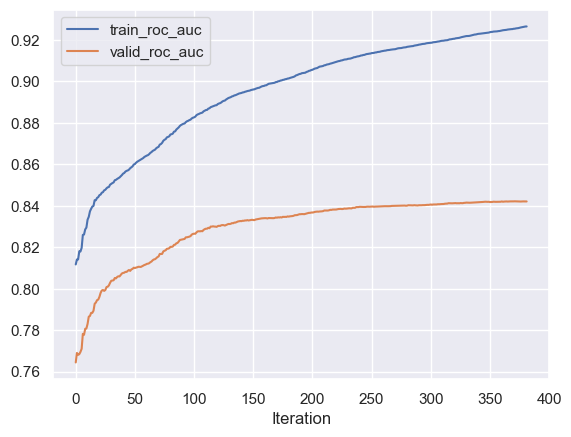

Train ROC-AUC 0.9254
Valid ROC-AUC 0.8422
Test ROC-AUC 0.8505


In [41]:
base_model_params = {
    "max_depth": 6,
    "min_samples_leaf": 14,
}

model = Boosting(
    base_model_params=base_model_params,
    n_estimators=500,
    learning_rate=0.1,
    early_stopping_rounds=10,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=True,
)

model.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid),
    use_best_model=True,
)

model.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {model.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {model.score(X_test, y_test):.4f}')


In [42]:
importances = model.feature_importances_

top = np.argsort(importances)[::-1][:10]

for i in top:
    print(all_features[i], importances[i])

occ 0.3578799868120221
ind 0.19166440342144078
incwage 0.10444909558302432
hrwage 0.08433878718559597
annhrs 0.07090580099590427
age 0.06561377755667183
year 0.04735931999118231
sch 0.0367906662245543
region 0.028302706444099105
race 0.011747881007838922


Наиболее значимыми признаками оказались тип профессии и индустрии.

 24%|██▍       | 119/500 [00:02<00:08, 45.77it/s]

Early stopping at iteration 119


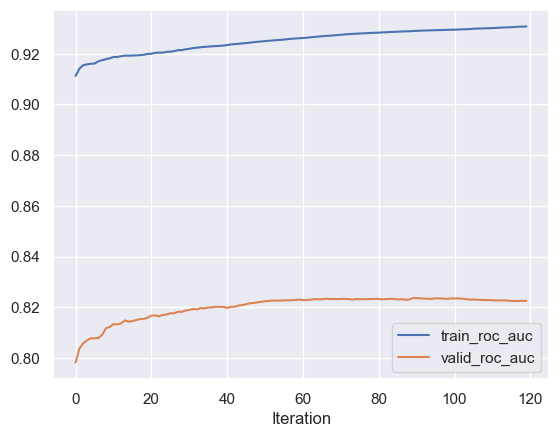

Train ROC-AUC 0.9290
Valid ROC-AUC 0.8237
Test ROC-AUC 0.8227


In [12]:
X = df.drop("sex", axis=1)
y = df["sex"]

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.2, random_state=1337
)
X_test, X_valid, y_test, y_valid = train_test_split(
    X_test, y_test, test_size=0.5, random_state=1337
)

cat_features = ["region", "race", "occupation", "empstat", "occ", "ind"]
all_features = list(X.columns)

encoder = CatEncoder(cat_features=cat_features)

encoder.fit(X_train, y_train, all_features)

X_train_enc = encoder.transform(X_train, all_features)
X_valid_enc = encoder.transform(X_valid, all_features)
X_test_enc = encoder.transform(X_test, all_features)

num_features = [
    i for i, f in enumerate(all_features)
    if f not in cat_features
]

quantizer = Quantize(
    quantization_type="uniform",
    nbins=255
)

quantizer.fit(X_train_enc, num_features)

X_train_u = quantizer.transform(X_train_enc)
X_valid_u = quantizer.transform(X_valid_enc)
X_test_u  = quantizer.transform(X_test_enc)

base_model_params = {
    "max_depth": 6,
    "min_samples_leaf": 14,
}

model_enc = Boosting(
    base_model_params=base_model_params,
    n_estimators=500,
    learning_rate=0.1,
    early_stopping_rounds=30,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=True,
    subsample=0.7,
    bagging_temperature=1.0,
    bootstrap_type='Bernoulli'
)

model_enc.fit(
    X_train_u,
    y_train,
    eval_set=(X_valid_u, y_valid),
    use_best_model=True,
)

model_enc.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model_enc.score(X_train_u, y_train):.4f}')
print(f'Valid ROC-AUC {model_enc.score(X_valid_u, y_valid):.4f}')
print(f'Test ROC-AUC {model_enc.score(X_test_u, y_test):.4f}')


In [13]:
importances = model_enc.feature_importances_

top = np.argsort(importances)[::-1][:10]

for i in top:
    print(all_features[i], importances[i])

occ 0.7212036915127666
ind 0.10154083862864641
incwage 0.04406435749047248
annhrs 0.036382272545770596
age 0.027392033986060108
sch 0.01705127391213092
occupation 0.013488064291697273
year 0.012774168683300901
region 0.01265725646854375
hrwage 0.009844105888954197


### Бонус. DART (1 балл)

Ранее мы обсуждали, что каждый базовый алгоритм пытается исправить ошибки всего предыдущего ансамбля. Из-за этого возникает неравноправие — каждая новая модель вносит все меньший и меньший вклад. Уверенные обучатели нейросетей знают, что это может привести к переобучению, если проводить аналогию с весами. Но выход есть, и выход этот [DART](https://arxiv.org/pdf/1505.01866)!

> В DL есть такой вид регуляризации, как dropout, когда некоторые узлы нейросети со случайным шансом отключаются. Можно попробовать обобщить этот подход на случай бустингов и случайно выкидывать деревья из композиции во время обучения

1. Выбираем, какие деревья убрать. При подсчете антиградиента берем не весь ансамбль, а только ту часть, что осталась
2. Домножаем выходы дерева на $1/k$, где $k$ — число удаленных деревьев, чтобы учесть тот факт, что ансамбль был не весь. Тогда вклад отдельного дерева будет не настолько большим
3. Домножаем выходы выкинутых деревьев на $k/(k+1)$, чтобы масштабы выходов примерно совпадали

Параметры, которые нужно добавить:

- `dart: bool = False` — DART бустинг или нет
- `dropout_rate: float = 0.05` — доля деревьев, которую выкидываем во время обучения DART

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>XGBClassifier(booster="dart")</code></td>
<td align="center"><code>LGBMClassifier(boosting_type="dart")</code></td>
<td align="center"><code>-</code></td>
</tr>
</table>

</div>

Попробуйте обучить DART на наших данных. Статью читать настоятельно рекомендуется, метод не самый простой

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚

------

## Задание 3. Около бустинга (2.5 балла | 0.5 бонус)

Теперь давайте проанализируем, как же правильно готовить бустинги. Нас интересует: как тюнить бустинги, какие они вообще бывают и как их интерпретировать. Посмотрим на все это по порядку

### 3.1. Optuna наносит ответный удар (0.5 балла)

Если вы помните, у нас уже было знакомство с библиотекой `optuna` для подбора гиперпараметров. Вспомним, как это делается и подумаем, как это можно делать еще лучше

Подберите на валидации оптимальные значения следующих гиперпараметров для вашей реализации бустинга:
- `max_depth`
- `n_estimators`
- `learning_rate`

Подберите диапазон параметров самостоятельно, не забывайте фиксировать сид (нет, его не нужно перебирать). Сохраните и покажите оптимальный набор параметров. Покажите, какие из них дали наибольший прирост (для этого придется почитать документацию оптуны)

In [26]:
import optuna

def objective(study, model="custom_boosting"):

    # параметры бустинга
    boosting_params = {
        "n_estimators": study.suggest_int("n_estimators", 50, 400),
        "learning_rate": study.suggest_float("learning_rate", 0.001, 0.2, log=True)
    }

    # параметры дерева
    tree_params = {
        "max_depth": study.suggest_int("max_depth", 2, 8),
        "min_samples_leaf": study.suggest_int("min_samples_leaf", 1, 50)
    }

    # параметры, зависящие от некоторого условия (e.g. subsample только для Bernoulli)
    # если не делать их условными, можно испортить процесс оптимизации
    # conditional_params = {}

    # bootstrap_type = study.suggest_categorical(
    #     "bootstrap_type", ["None", "Bernoulli", "Bayesian"]
    # )

    # if bootstrap_type == "None":
    #     conditional_params["bootstrap_type"] = None
    #     conditional_params["subsample"] = 1.0
    #     conditional_params["bagging_temperature"] = 1.0

    # elif bootstrap_type == "Bernoulli":
    #     conditional_params["bootstrap_type"] = "Bernoulli"
    #     conditional_params["subsample"] = study.suggest_float("subsample", 0.5, 1.0)
    #     conditional_params["bagging_temperature"] = 1.0

    # elif bootstrap_type == "Bayesian":
    #     conditional_params["bootstrap_type"] = "Bayesian"
    #     conditional_params["subsample"] = study.suggest_float("subsample", 0.5, 1.0)
    #     conditional_params["bagging_temperature"] = study.suggest_float("bagging_temperature", 0.1, 10.0, log=True)

    # conditional_params["rsm"] = study.suggest_float("rsm", 0.5, 1.0)

    model_opt = Boosting(
        base_model_params=tree_params,
        n_estimators=boosting_params["n_estimators"],
        learning_rate=boosting_params["learning_rate"],
        early_stopping_rounds=10,
        eval_metric="valid_roc_auc",
        random_state=69,
        verbose=False
    )

    model_opt.fit(
        X_train,
        y_train,
        eval_set=(X_valid, y_valid),
        use_best_model=True
    )

    return model_opt.score(X_valid, y_valid)

In [27]:
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=69)
)

study.optimize(objective, n_trials=50)

print("Best ROC-AUC:", study.best_value)
print("Best params:")
for k, v in study.best_params.items():
    print(f"{k}: {v}")

[I 2025-12-18 09:56:06,057] A new study created in memory with name: no-name-ade2645e-0874-4add-aedf-c410f2c25444
[I 2025-12-18 09:56:08,606] Trial 0 finished with value: 0.817257269029076 and parameters: {'n_estimators': 153, 'learning_rate': 0.07272589628908209, 'max_depth': 4, 'min_samples_leaf': 40}. Best is trial 0 with value: 0.817257269029076.
[I 2025-12-18 09:56:08,749] Trial 1 finished with value: 0.6519086076344305 and parameters: {'n_estimators': 247, 'learning_rate': 0.0038327967556224534, 'max_depth': 2, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.817257269029076.
[I 2025-12-18 09:56:14,670] Trial 2 finished with value: 0.8274653098612396 and parameters: {'n_estimators': 286, 'learning_rate': 0.04033917134658513, 'max_depth': 7, 'min_samples_leaf': 40}. Best is trial 2 with value: 0.8274653098612396.
[I 2025-12-18 09:56:14,910] Trial 3 finished with value: 0.7691510766043064 and parameters: {'n_estimators': 76, 'learning_rate': 0.00538260588466923, 'max_depth': 7

Best ROC-AUC: 0.8341713366853467
Best params:
n_estimators: 309
learning_rate: 0.0813638638821094
max_depth: 5
min_samples_leaf: 42


Не включила в перебор некоторые параметры, так как они ранее показали более низкое качество при использовании по сравнению с моделью где они отсутствуют.

 92%|█████████▏| 285/309 [00:05<00:00, 51.44it/s]

Early stopping at iteration 285


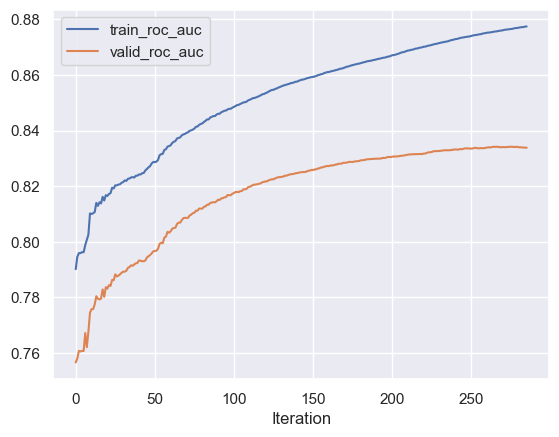

Train ROC-AUC 0.8765
Valid ROC-AUC 0.8342
Test ROC-AUC 0.8336


In [28]:
base_best_params = study.best_params

base_model_params = {
    "max_depth": base_best_params.pop("max_depth"), 
    "min_samples_leaf": base_best_params.pop("min_samples_leaf"),
}


model_final = Boosting(
    base_model_params=base_model_params,
    **base_best_params, 
    early_stopping_rounds=10,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=True,
)

model_final.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid),
    use_best_model=True,
)

# 5. Оценка результатов
model_final.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model_final.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {model_final.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {model_final.score(X_test, y_test):.4f}')

In [14]:
X = df.drop("sex", axis=1)
y = df["sex"]

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.2, random_state=1337
)
X_test, X_valid, y_test, y_valid = train_test_split(
    X_test, y_test, test_size=0.5, random_state=1337
)

cat_features = ["region", "race", "occupation", "empstat", "occ", "ind"]
all_features = list(X.columns)

encoder = CatEncoder(cat_features=cat_features)

encoder.fit(X_train, y_train, all_features)

X_train_enc = encoder.transform(X_train, all_features)
X_valid_enc = encoder.transform(X_valid, all_features)
X_test_enc = encoder.transform(X_test, all_features)

num_features = [
    i for i, f in enumerate(all_features)
    if f not in cat_features
]

quantizer = Quantize(
    quantization_type="uniform",
    nbins=255
)

quantizer.fit(X_train_enc, num_features)

X_train_u = quantizer.transform(X_train_enc)
X_valid_u = quantizer.transform(X_valid_enc)
X_test_u  = quantizer.transform(X_test_enc)


In [16]:
def objective(study, X_train, y_train, X_valid, y_valid):

    # параметры бустинга
    boosting_params = {
        "n_estimators": study.suggest_int("n_estimators", 50, 400),
        "learning_rate": study.suggest_float("learning_rate", 0.001, 0.2, log=True)
    }

    # параметры дерева
    tree_params = {
        "max_depth": study.suggest_int("max_depth", 2, 8),
        "min_samples_leaf": study.suggest_int("min_samples_leaf", 1, 50)
    }

    # параметры, зависящие от некоторого условия (e.g. subsample только для Bernoulli)
    # если не делать их условными, можно испортить процесс оптимизации
    conditional_params = {}

    bootstrap_type = study.suggest_categorical(
        "bootstrap_type", ["None", "Bernoulli", "Bayesian"]
    )

    if bootstrap_type == "None":
        conditional_params["bootstrap_type"] = None
        conditional_params["subsample"] = 1.0
        conditional_params["bagging_temperature"] = 1.0

    elif bootstrap_type == "Bernoulli":
        conditional_params["bootstrap_type"] = "Bernoulli"
        conditional_params["subsample"] = study.suggest_float("subsample", 0.5, 1.0)
        conditional_params["bagging_temperature"] = 1.0

    elif bootstrap_type == "Bayesian":
        conditional_params["bootstrap_type"] = "Bayesian"
        conditional_params["subsample"] = study.suggest_float("subsample", 0.5, 1.0)
        conditional_params["bagging_temperature"] = study.suggest_float("bagging_temperature", 0.1, 10.0, log=True)

    conditional_params["rsm"] = study.suggest_float("rsm", 0.5, 1.0)

    model_opt = Boosting(
        base_model_params=tree_params,
        n_estimators=boosting_params["n_estimators"],
        learning_rate=boosting_params["learning_rate"],
        early_stopping_rounds=20,
        eval_metric="valid_roc_auc",
        random_state=69,
        verbose=False,
        **conditional_params
    )

    model_opt.fit(
        X_train,
        y_train,
        eval_set=(X_valid, y_valid),
        use_best_model=True
    )

    return model_opt.score(X_valid, y_valid)


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=69)
)

study.optimize(
lambda study: objective(study, X_train_u, y_train, X_valid_u, y_valid), 
    n_trials=50
)

print("Best ROC-AUC:", study.best_value)
print("Best params:")
for k, v in study.best_params.items():
    print(f"{k}: {v}")

[I 2025-12-17 23:21:33,028] A new study created in memory with name: no-name-85143049-7a7a-4d7d-8f05-8868a6c84a1a
[I 2025-12-17 23:21:33,641] Trial 0 finished with value: 0.820937283749135 and parameters: {'n_estimators': 153, 'learning_rate': 0.07272589628908209, 'max_depth': 4, 'min_samples_leaf': 40, 'bootstrap_type': 'None', 'rsm': 0.5292303645984399}. Best is trial 0 with value: 0.820937283749135.
[I 2025-12-17 23:21:33,957] Trial 1 finished with value: 0.8075592302369211 and parameters: {'n_estimators': 286, 'learning_rate': 0.04033917134658513, 'max_depth': 7, 'min_samples_leaf': 40, 'bootstrap_type': 'Bayesian', 'subsample': 0.664247114587524, 'bagging_temperature': 0.8715473161163867, 'rsm': 0.5905428588673421}. Best is trial 0 with value: 0.820937283749135.
[I 2025-12-17 23:21:34,319] Trial 2 finished with value: 0.809191236764947 and parameters: {'n_estimators': 163, 'learning_rate': 0.01113660228142777, 'max_depth': 5, 'min_samples_leaf': 15, 'bootstrap_type': 'Bernoulli', 

Best ROC-AUC: 0.8294553178212714
Best params:
n_estimators: 140
learning_rate: 0.1172885513270026
max_depth: 2
min_samples_leaf: 17
bootstrap_type: None
rsm: 0.8785427258560626


In [17]:
all_best_params = study.best_params

### 3.2. Глубокая оптимизация (1 балл)

Помимо эффективного перебора гиперпараметров, `optuna` предлагает более тонкий контроль над самой процедурой обучения

1. Посмотрите, как можно контролировать процесс обучения бустинга при помощи прунера. У библиотечных имплементаций есть уже готовые, их можно использовать пунктом ниже. Для кастомной модели возьмите что-то из [`optuna.pruners`](https://optuna.readthedocs.io/en/stable/reference/pruners.html), либо можно написать своё. Идея прунера — не обучать бустинг до конца, если по истории валидации видно, что другие бустинги на этом этапе статистически лучше, для этого мы и делали `partial_fit`.
2. Если мы ценим наше время, можно внести в процесс оптимизации немного определенности и, например, сказать, что если мы достигли определенного качества, то этого нам уже хватит с головой. Объект со смешным названием [`optuna.terminator`](https://optuna.readthedocs.io/en/stable/reference/terminator.html) позволяет нам остановить оптимизацию по достижении некоторого трешхолда по какому-либо параметру, который мы сами придумали, например, качестве на тесте

Чего от вас хочет автор?
1. Добавьте другие параметры, которые вы реализовали во время выполнения дз, в `objective`, они хорошие и могут вам помочь
1. Попробуйте ускорить оптимизацию при помощи своего или библиотечного прунера и/или терминатора. Если ускорения нет, скорее всего, вы вставили его неправильно
2. Побейте трешхолд ROC-AUC в 0.84 на тесте, если в предыдущем пункте этого сделать не удалось

In [35]:
from optuna.exceptions import TrialPruned
from optuna.pruners import MedianPruner
from sklearn.metrics import roc_auc_score

# предобработка
X = df.drop("sex", axis=1)
y = df["sex"]

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.2, random_state=1337
)
X_test, X_valid, y_test, y_valid = train_test_split(
    X_test, y_test, test_size=0.5, random_state=1337
)

cat_features = ["region", "race", "occupation", "empstat", "occ", "ind"]
all_features = list(X.columns)

encoder = CatEncoder(cat_features=cat_features)

encoder.fit(X_train, y_train, all_features)

X_train_enc = encoder.transform(X_train, all_features)
X_valid_enc = encoder.transform(X_valid, all_features)
X_test_enc = encoder.transform(X_test, all_features)

num_features = [
    i for i, f in enumerate(all_features)
    if f not in cat_features
]

quantizer = Quantize(
    quantization_type="uniform",
    nbins=255
)

quantizer.fit(X_train_enc, num_features)

X_train_u = quantizer.transform(X_train_enc)
X_valid_u = quantizer.transform(X_valid_enc)
X_test_u  = quantizer.transform(X_test_enc)


# функция
def objective(study, X_train, y_train, X_valid, y_valid):

    # параметры бустинга
    boosting_params = {
        "n_estimators": study.suggest_int("n_estimators", 50, 400),
        "learning_rate": study.suggest_float("learning_rate", 0.001, 0.2, log=True)
    }

    # параметры дерева
    tree_params = {
        "max_depth": study.suggest_int("max_depth", 2, 8),
        "min_samples_leaf": study.suggest_int("min_samples_leaf", 1, 50)
    }

    # параметры, зависящие от некоторого условия (e.g. subsample только для Bernoulli)
    # если не делать их условными, можно испортить процесс оптимизации
    conditional_params = {}

    bootstrap_type = study.suggest_categorical(
        "bootstrap_type", ["None", "Bernoulli", "Bayesian"]
    )

    if bootstrap_type == "None":
        conditional_params["bootstrap_type"] = None
        conditional_params["subsample"] = 1.0
        conditional_params["bagging_temperature"] = 1.0

    elif bootstrap_type == "Bernoulli":
        conditional_params["bootstrap_type"] = "Bernoulli"
        conditional_params["subsample"] = study.suggest_float("subsample", 0.5, 1.0)
        conditional_params["bagging_temperature"] = 1.0

    elif bootstrap_type == "Bayesian":
        conditional_params["bootstrap_type"] = "Bayesian"
        conditional_params["subsample"] = study.suggest_float("subsample", 0.5, 1.0)
        conditional_params["bagging_temperature"] = study.suggest_float("bagging_temperature", 0.1, 10.0, log=True)

    conditional_params["rsm"] = study.suggest_float("rsm", 0.5, 1.0)

    model_opt = Boosting(
        base_model_params=tree_params,
        n_estimators=boosting_params["n_estimators"],
        learning_rate=boosting_params["learning_rate"],
        early_stopping_rounds=20,
        eval_metric="valid_roc_auc",
        random_state=69,
        verbose=False,
        **conditional_params
    )

    model_opt.train_predictions = np.zeros(X_train_enc.shape[0])
    valid_predictions = np.zeros(X_valid_enc.shape[0])

    for i in range(model_opt.n_estimators):
      
        model_opt.partial_fit(X_train_enc, y_train) 
        
        valid_predictions += (
            model_opt.learning_rate * model_opt.gammas[-1] * model_opt.models[-1].predict(X_valid_enc[:, model_opt.feature_masks[-1]])
        )

        valid_roc_auc = roc_auc_score(y_valid == 1, model_opt.sigmoid(valid_predictions))

        study.report(valid_roc_auc, step=i) 
        
        if study.should_prune():
            raise TrialPruned() 
        
    return valid_roc_auc


# перебор
pruner = optuna.pruners.MedianPruner(
    n_startup_trials=10,
    n_warmup_steps=20,
    interval_steps=5,
)

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=69),
    pruner=pruner,
)

study.optimize(
    lambda study: objective(study, X_train_u, y_train, X_valid_u, y_valid),
    n_trials=100,
)


print("Best ROC-AUC:", study.best_value)
print("Best params:")
for k, v in study.best_params.items():
    print(f"{k}: {v}")

[I 2025-12-18 10:38:51,657] A new study created in memory with name: no-name-060464ab-1081-4da8-b273-f5e0349d030f
[I 2025-12-18 10:38:54,196] Trial 0 finished with value: 0.8217932871731486 and parameters: {'n_estimators': 153, 'learning_rate': 0.07272589628908209, 'max_depth': 4, 'min_samples_leaf': 40, 'bootstrap_type': 'None', 'rsm': 0.5292303645984399}. Best is trial 0 with value: 0.8217932871731486.
[I 2025-12-18 10:38:58,796] Trial 1 finished with value: 0.80562322249289 and parameters: {'n_estimators': 286, 'learning_rate': 0.04033917134658513, 'max_depth': 7, 'min_samples_leaf': 40, 'bootstrap_type': 'Bayesian', 'subsample': 0.664247114587524, 'bagging_temperature': 0.8715473161163867, 'rsm': 0.5905428588673421}. Best is trial 0 with value: 0.8217932871731486.
[I 2025-12-18 10:39:01,931] Trial 2 finished with value: 0.8172452689810759 and parameters: {'n_estimators': 163, 'learning_rate': 0.01113660228142777, 'max_depth': 5, 'min_samples_leaf': 15, 'bootstrap_type': 'Bernoulli'

Best ROC-AUC: 0.8288253153012612
Best params:
n_estimators: 280
learning_rate: 0.07163252099778158
max_depth: 4
min_samples_leaf: 37
bootstrap_type: None
rsm: 0.8197111460516749


In [37]:
all_best_params_prune = study.best_params

In [22]:
from optuna.exceptions import TrialPruned
from optuna.pruners import MedianPruner
from sklearn.metrics import roc_auc_score

# предобработка
X = df[["occ", "ind", "incwage", "hrwage", "annhrs"]]
y = df["sex"]

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.2, random_state=1337
)
X_test, X_valid, y_test, y_valid = train_test_split(
    X_test, y_test, test_size=0.5, random_state=1337
)

cat_features = ["occ", "ind"]
all_features = list(X.columns)

encoder = CatEncoder(cat_features=cat_features)

encoder.fit(X_train, y_train, all_features)

X_train_enc = encoder.transform(X_train, all_features)
X_valid_enc = encoder.transform(X_valid, all_features)
X_test_enc = encoder.transform(X_test, all_features)

num_features = [
    i for i, f in enumerate(all_features)
    if f not in cat_features
]

quantizer = Quantize(
    quantization_type="quantile",
    nbins=255
)

quantizer.fit(X_train_enc, num_features)

X_train_u = quantizer.transform(X_train_enc)
X_valid_u = quantizer.transform(X_valid_enc)
X_test_u  = quantizer.transform(X_test_enc)


# функция
def objective(study, X_train, y_train, X_valid, y_valid):

    # параметры бустинга
    boosting_params = {
        "n_estimators": study.suggest_int("n_estimators", 50, 400),
        "learning_rate": study.suggest_float("learning_rate", 0.001, 0.2, log=True)
    }

    # параметры дерева
    tree_params = {
        "max_depth": study.suggest_int("max_depth", 2, 8),
        "min_samples_leaf": study.suggest_int("min_samples_leaf", 1, 50)
    }

    # параметры, зависящие от некоторого условия (e.g. subsample только для Bernoulli)
    # если не делать их условными, можно испортить процесс оптимизации
    conditional_params = {}

    bootstrap_type = study.suggest_categorical(
        "bootstrap_type", ["None", "Bernoulli", "Bayesian"]
    )

    if bootstrap_type == "None":
        conditional_params["bootstrap_type"] = None
        conditional_params["subsample"] = 1.0
        conditional_params["bagging_temperature"] = 1.0

    elif bootstrap_type == "Bernoulli":
        conditional_params["bootstrap_type"] = "Bernoulli"
        conditional_params["subsample"] = study.suggest_float("subsample", 0.5, 1.0)
        conditional_params["bagging_temperature"] = 1.0

    elif bootstrap_type == "Bayesian":
        conditional_params["bootstrap_type"] = "Bayesian"
        conditional_params["subsample"] = study.suggest_float("subsample", 0.5, 1.0)
        conditional_params["bagging_temperature"] = study.suggest_float("bagging_temperature", 0.1, 10.0, log=True)

    conditional_params["rsm"] = study.suggest_float("rsm", 0.5, 1.0)

    model_opt = Boosting(
        base_model_params=tree_params,
        n_estimators=boosting_params["n_estimators"],
        learning_rate=boosting_params["learning_rate"],
        early_stopping_rounds=20,
        eval_metric="valid_roc_auc",
        random_state=69,
        verbose=False,
        **conditional_params
    )

    model_opt.train_predictions = np.zeros(X_train_enc.shape[0])
    valid_predictions = np.zeros(X_valid_enc.shape[0])

    for i in range(model_opt.n_estimators):
      
        model_opt.partial_fit(X_train_enc, y_train) 
        
        valid_predictions += (
            model_opt.learning_rate * model_opt.gammas[-1] * model_opt.models[-1].predict(X_valid_enc[:, model_opt.feature_masks[-1]])
        )

        valid_roc_auc = roc_auc_score(y_valid == 1, model_opt.sigmoid(valid_predictions))

        study.report(valid_roc_auc, step=i) 
        
        if study.should_prune():
            raise TrialPruned() 
        
    return valid_roc_auc


# перебор
pruner = optuna.pruners.MedianPruner(
    n_startup_trials=10,
    n_warmup_steps=20,
    interval_steps=5,
)

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=69),
    pruner=pruner,
)

study.optimize(
    lambda study: objective(study, X_train_u, y_train, X_valid_u, y_valid),
    n_trials=100,
)


print("Best ROC-AUC:", study.best_value)
print("Best params:")
for k, v in study.best_params.items():
    print(f"{k}: {v}")

[I 2025-12-18 08:46:46,061] A new study created in memory with name: no-name-b0eda92f-127d-4f5b-804d-8786274a979f
[I 2025-12-18 08:46:48,010] Trial 0 finished with value: 0.8183192732770931 and parameters: {'n_estimators': 153, 'learning_rate': 0.07272589628908209, 'max_depth': 4, 'min_samples_leaf': 40, 'bootstrap_type': 'None', 'rsm': 0.5292303645984399}. Best is trial 0 with value: 0.8183192732770931.
[I 2025-12-18 08:46:51,731] Trial 1 finished with value: 0.7497729990919965 and parameters: {'n_estimators': 286, 'learning_rate': 0.04033917134658513, 'max_depth': 7, 'min_samples_leaf': 40, 'bootstrap_type': 'Bayesian', 'subsample': 0.664247114587524, 'bagging_temperature': 0.8715473161163867, 'rsm': 0.5905428588673421}. Best is trial 0 with value: 0.8183192732770931.
[I 2025-12-18 08:46:53,728] Trial 2 finished with value: 0.8189852759411039 and parameters: {'n_estimators': 163, 'learning_rate': 0.01113660228142777, 'max_depth': 5, 'min_samples_leaf': 15, 'bootstrap_type': 'Bernoull

Best ROC-AUC: 0.8270213080852324
Best params:
n_estimators: 308
learning_rate: 0.011085000641377834
max_depth: 8
min_samples_leaf: 48
bootstrap_type: None
rsm: 0.8757052164781236


 26%|██▌       | 72/280 [00:01<00:04, 51.37it/s]


Early stopping at iteration 72


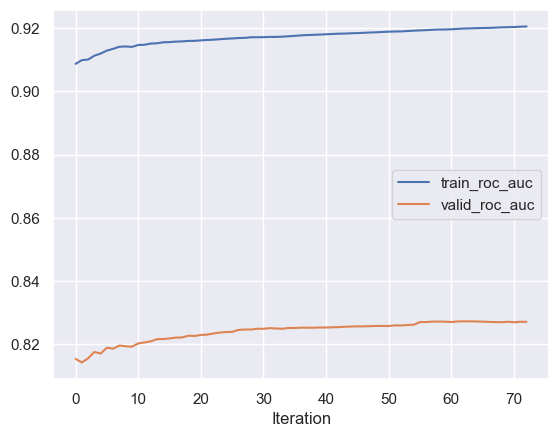

Train ROC-AUC 0.9199
Valid ROC-AUC 0.8273
Test ROC-AUC 0.8246


In [41]:
# предобработка

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.2, random_state=1337
)
X_test, X_valid, y_test, y_valid = train_test_split(
    X_test, y_test, test_size=0.5, random_state=1337
)

cat_features = ["region", "race", "occupation", "empstat", "occ", "ind"]
all_features = list(X.columns)

encoder = CatEncoder(cat_features=cat_features)

encoder.fit(X_train, y_train, all_features)

X_train_enc = encoder.transform(X_train, all_features).astype(float)
X_valid_enc = encoder.transform(X_valid, all_features).astype(float)
X_test_enc = encoder.transform(X_test, all_features).astype(float)

num_features = [
    i for i, f in enumerate(all_features)
    if f not in cat_features
]

quantizer = Quantize(
    quantization_type="quantile",
    nbins=255
)

quantizer.fit(X_train_enc, num_features)

X_train_u = quantizer.transform(X_train_enc)
X_valid_u = quantizer.transform(X_valid_enc)
X_test_u  = quantizer.transform(X_test_enc)

base_model_params_full = {
    "max_depth": all_best_params_prune.pop("max_depth"), 
    "min_samples_leaf": all_best_params_prune.pop("min_samples_leaf"),
}


model_final_full = Boosting(
    base_model_params=base_model_params,
    **all_best_params_prune, 
    early_stopping_rounds=10,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=True,
)

model_final_full.fit(
    X_train_u,
    y_train,
    eval_set=(X_valid_u, y_valid),
    use_best_model=True,
)

# 5. Оценка результатов
model_final_full.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model_final_full.score(X_train_u, y_train):.4f}')
print(f'Valid ROC-AUC {model_final_full.score(X_valid_u, y_valid):.4f}')
print(f'Test ROC-AUC {model_final_full.score(X_test_u, y_test):.4f}')

### 3.3. Готовые реализации (0.5 балла)

Библиотек для бустингов существует много, но активно используются лишь три. Вам предстоит попробовать их в деле, посмотреть на их уникальные фишки и понять, что вам нравится больше всего

Возьмите любую из популярных библиотек: <font color='#2f82d4'>XGBoost</font>, <font color='#53c96c'>LightGBM</font> или <font color='#c4bf0a'>CatBoost</font>.
Ваша задача — взять одну из них, подобрать те же оптимальные параметры, что и выше, и сравнить две оптимизированные модели по
- динамике функции потерь (на обучающей и на валидационной выборке)
- времени обучения
- оптимальному набору гиперпараметров

In [63]:
#!pip install catboost

In [65]:
all_features = list(X.columns)
all_features

['region',
 'age',
 'year',
 'race',
 'sch',
 'empstat',
 'occ',
 'ind',
 'annhrs',
 'hrwage',
 'incwage',
 'occupation']

In [79]:
from catboost import CatBoostClassifier

cat_features = ["occupation", "empstat", "occ", "ind"]
all_features = ['age', 'sch', 'empstat', 'occ', 'ind', 'annhrs', 'hrwage', 'incwage', 'occupation'] # отсеяла наименее важные
cat_features_idx = [all_features.index(f) for f in cat_features]

X = df[['age', 'sch', 'empstat', 'occ', 'ind', 'annhrs', 'hrwage', 'incwage', 'occupation']]
y = df["sex"]

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.2, random_state=1337
)
X_test, X_valid, y_test, y_valid = train_test_split(
    X_test, y_test, test_size=0.5, random_state=1337
)

def objective_catboost(study, X_train, y_train, X_valid, y_valid, cat_features_idx):

    boosting_params = {
        "iterations": study.suggest_int("iterations", 50, 400),
        "learning_rate": study.suggest_float("learning_rate", 0.001, 0.2, log=True)
    }

    tree_params = {
        "depth": study.suggest_int("depth", 2, 8),
        "min_data_in_leaf": study.suggest_int("min_data_in_leaf", 1, 50)
    }

    subsample = study.suggest_float("subsample", 0.5, 1.0)
    colsample_bylevel = study.suggest_float("colsample_bylevel", 0.5, 1.0)

    model_catboost = CatBoostClassifier(
        iterations=boosting_params["iterations"],
        learning_rate=boosting_params["learning_rate"],
        depth=tree_params["depth"],
        min_data_in_leaf=tree_params["min_data_in_leaf"],
        subsample=subsample,
        colsample_bylevel=colsample_bylevel,
        eval_metric="AUC",
        random_seed=69,
        early_stopping_rounds=20,
        verbose=0,
    )

    model_catboost.fit(
        X_train, y_train,
        eval_set=(X_valid, y_valid),
        cat_features=cat_features_idx,
        use_best_model=True
    )

    return roc_auc_score(y_valid, model_catboost.predict_proba(X_valid)[:, 1])


study_cb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=69)
)

X_train_cb = X_train.copy().astype(object)
X_valid_cb = X_valid.copy().astype(object)
X_test_cb  = X_test.copy().astype(object)

for idx in cat_features_idx:
    X_train_cb[:, idx] = X_train_cb[:, idx].astype(str)
    X_valid_cb[:, idx] = X_valid_cb[:, idx].astype(str)
    X_test_cb[:, idx]  = X_test_cb[:, idx].astype(str)

study_cb.optimize(
    lambda s: objective_catboost(s, X_train_cb, y_train, X_valid_cb, y_valid, cat_features_idx),
    n_trials=50
)

print("Best ROC-AUC:", study_cb.best_value)
print("Best params:")
for k, v in study_cb.best_params.items():
    print(f"{k}: {v}")


[I 2025-12-18 12:28:29,016] A new study created in memory with name: no-name-ab22d06c-c14e-48e8-8e38-aea752587d3d
[I 2025-12-18 12:28:29,195] Trial 0 finished with value: 0.8555674222696892 and parameters: {'iterations': 153, 'learning_rate': 0.07272589628908209, 'depth': 4, 'min_data_in_leaf': 40, 'subsample': 0.7806744878852863, 'colsample_bylevel': 0.6267944771100666}. Best is trial 0 with value: 0.8555674222696892.
[I 2025-12-18 12:28:29,292] Trial 1 finished with value: 0.8384253537014148 and parameters: {'iterations': 86, 'learning_rate': 0.0013630754360282723, 'depth': 6, 'min_data_in_leaf': 35, 'subsample': 0.866391602975827, 'colsample_bylevel': 0.8939370292488552}. Best is trial 0 with value: 0.8555674222696892.
[I 2025-12-18 12:28:29,418] Trial 2 finished with value: 0.8413593654374618 and parameters: {'iterations': 76, 'learning_rate': 0.00538260588466923, 'depth': 7, 'min_data_in_leaf': 17, 'subsample': 0.7350727424600221, 'colsample_bylevel': 0.5905428588673421}. Best is 

Best ROC-AUC: 0.8650994603978416
Best params:
iterations: 387
learning_rate: 0.1466115314728663
depth: 5
min_data_in_leaf: 27
subsample: 0.9667970054563703
colsample_bylevel: 0.9337649398895237


<font color='#b962c4'>**Вопрос:** Какая архитектура вам нравится больше всего и почему?</font>

<font color='#b962c4'>**Ответ**: ... </font> Я использовала CatBoost, поскольку он умеет работать с категеориальными признаками

### Бонус. Еще пара красивых слов (0.5 балла)

Разумеется, мы рассмотрели далеко не все классные фишки, которые есть в библиотеках. Ниже есть набор заданий, выберите одно, которое кажется вам наиболее интересным

- <font color='#2f82d4'>XGBoost</font> известен тем, что в нем впервые повилась регуляризация. Ручками ее написать сложно, но тут и не требуется. Добавьте обе регуляризации, что там есть, как параметры в оптуну и прогоните процесс оптимизации только на них. Оцените экспертно, насколько прямая регуляризация эффективна, по сравнению с регуляризацией деревьев
- <font color='#53c96c'>LightGBM</font> содержит в себе в том числе реализацию своего злейшего врага - случайный лес. Посмотрите, какие есть параметры у него, обучите и ответьте на <font color='#b962c4'>вопрос "кто победит: бустинг или лес? и почему?" </font>
- <font color='#c4bf0a'>CatBoost</font> славится множеством функций, кажется в этом ноутбуке, только про них и говорили. Славится он еще и кучей разных подходов к обучению деревьев, в частности он умеет мерджить несколько моделей в одно. Это не стекинг, и даже не беггинг, а что-то поинтереснее. Попробоуйте разбить выборку на фолды и обучить по катбусту на каждом из них, а затем их склеить. Тюнить их не надо, он и так неплох, в этом его сила и мудрость. Оцените, насколько это круто по 10-балльной

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>alpha</code>, <code>lambda</code></td>
<td align="center"><code>boosting_type="rf"</code></td>
<td align="center"><code>sum_models</code>, <code>to_classifier</code></td>
</tr>
</table>

</div>

Посмотрите на выбранную вами фичу и покажите, как хорошо или плохо она работает

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚

### 3.4. Бустинг и вероятности (0.5 балла)

С качеством мы более-менее разобрались, но таки что насчет вероятностей? Постройте калибровочную кривую для вашей лучшей модели бустинга. Насколько хорошо бустинг оценивает вероятности?

Модель:

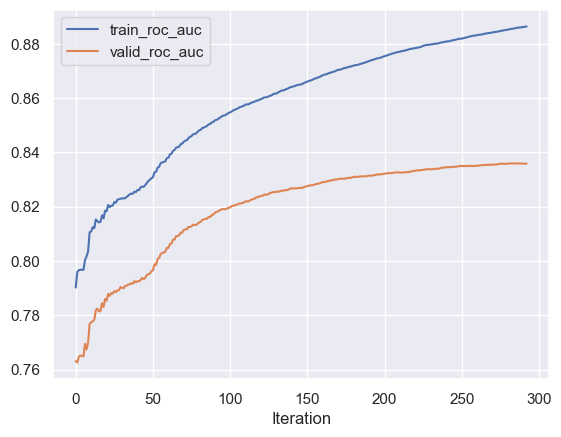

Train ROC-AUC 0.8855
Valid ROC-AUC 0.8359
Test ROC-AUC 0.8384


In [57]:
model_final = Boosting(
    base_model_params=base_model_params,
    **base_best_params, 
    early_stopping_rounds=10,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=False,
)

model_final.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid),
    use_best_model=True,
)

# 5. Оценка результатов
model_final.plot_history(["train_roc_auc", "valid_roc_auc"])

print(f'Train ROC-AUC {model_final.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {model_final.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {model_final.score(X_test, y_test):.4f}')

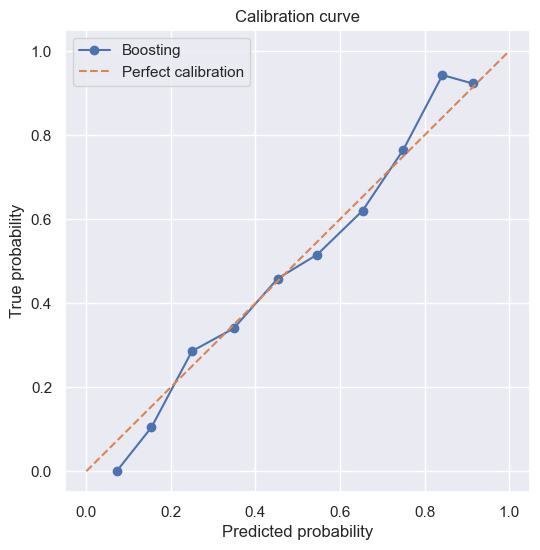

In [32]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

y_test_pred = model_final.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(
    y_test, y_test_pred, n_bins=10, strategy="uniform"
)

plt.figure(figsize=(6, 6))
plt.plot(prob_pred, prob_true, marker="o", label="Boosting")
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.xlabel("Predicted probability")
plt.ylabel("True probability")
plt.title("Calibration curve")
plt.legend()
plt.grid(True)
plt.show()

In [43]:
# предобработка

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.2, random_state=1337
)
X_test, X_valid, y_test, y_valid = train_test_split(
    X_test, y_test, test_size=0.5, random_state=1337
)

cat_features = ["region", "race", "occupation", "empstat", "occ", "ind"]
all_features = list(X.columns)

encoder = CatEncoder(cat_features=cat_features)

encoder.fit(X_train, y_train, all_features)

X_train_enc = encoder.transform(X_train, all_features).astype(float)
X_valid_enc = encoder.transform(X_valid, all_features).astype(float)
X_test_enc = encoder.transform(X_test, all_features).astype(float)

num_features = [
    i for i, f in enumerate(all_features)
    if f not in cat_features
]

quantizer = Quantize(
    quantization_type="quantile",
    nbins=255
)

quantizer.fit(X_train_enc, num_features)

X_train_u = quantizer.transform(X_train_enc)
X_valid_u = quantizer.transform(X_valid_enc)
X_test_u  = quantizer.transform(X_test_enc)


model_final_full = Boosting(
    base_model_params=base_model_params_full,
    **all_best_params_prune, 
    early_stopping_rounds=10,
    eval_metric="valid_roc_auc",
    random_state=69,
    verbose=False,
)

model_final_full.fit(
    X_train_u,
    y_train,
    eval_set=(X_valid_u, y_valid),
    use_best_model=True,
)

print(f'Train ROC-AUC {model_final_full.score(X_train_u, y_train):.4f}')
print(f'Valid ROC-AUC {model_final_full.score(X_valid_u, y_valid):.4f}')
print(f'Test ROC-AUC {model_final_full.score(X_test_u, y_test):.4f}')

Train ROC-AUC 0.9170
Valid ROC-AUC 0.8279
Test ROC-AUC 0.8249


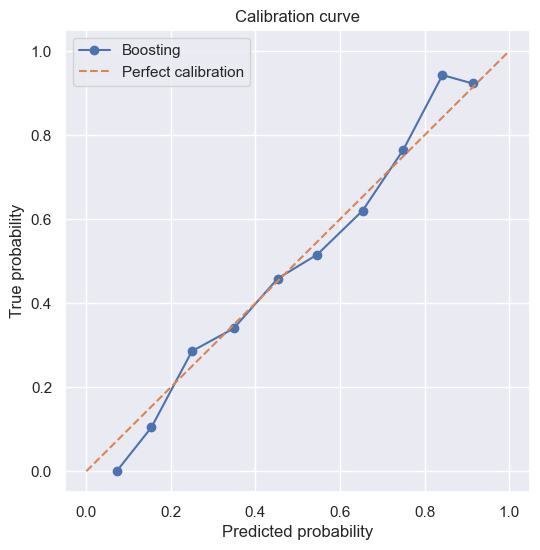

In [44]:
y_test_pred_full = model_final_full.predict_proba(X_test_u)[:, 1]

prob_true_full, prob_pred_full = calibration_curve(
    y_test, y_test_pred, n_bins=10, strategy="uniform"
)

plt.figure(figsize=(6, 6))
plt.plot(prob_pred_full, prob_true_full, marker="o", label="Boosting")
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.xlabel("Predicted probability")
plt.ylabel("True probability")
plt.title("Calibration curve")
plt.legend()
plt.grid(True)
plt.show()


Постройте также калибровочную кривую для логистической регрессии, сравните их между собой. Проанализируйте полученные результаты.

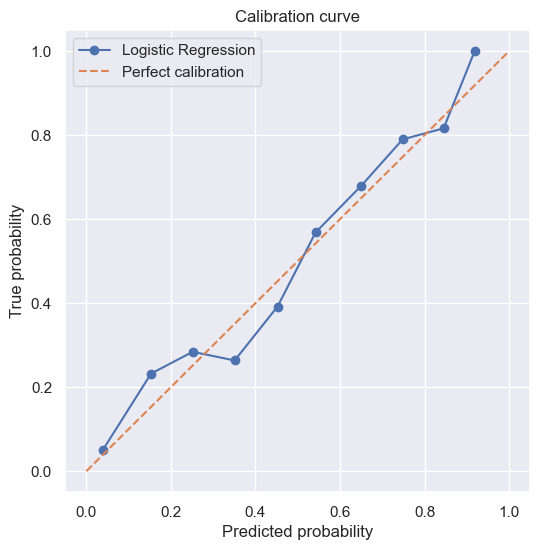

In [33]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

y_test_lr = lr.predict_proba(X_test)[:, 1]

prob_true_lr, prob_pred_lr = calibration_curve(
    y_test, y_test_lr, n_bins=10, strategy="uniform"
)

plt.figure(figsize=(6, 6))
plt.plot(prob_pred_lr, prob_true_lr, marker="o", label="Logistic Regression")
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.xlabel("Predicted probability")
plt.ylabel("True probability")
plt.title("Calibration curve")
plt.legend()
plt.grid(True)
plt.show()

Логистическая регрессия: для высоких вероятностей достаточно хорошо откалибровано, самые маленькие переоценивает, средние до 0.5 недооценивает.

Бустинг: в области низких вероятностей заметно недооценивает вероятность положительного класса, далее в средней области кривая близка к диагонали с небольшими колебаниями, вероятности 0.7-0.9 переоценивает.

В целом, несмотря на то, что логистическая регрессия считается эталоном калибровка, поскольку она напрямую минимизирует LogLoss, моя модель бустинга по графику кажется даже более откалиброванной

Конечно же, бустинг великолепен, как он есть, но можно сделать его еще лучше, если его откалибровать

1. Посмотрите на то, как это делать из библиотеки `sklearn`
2. Откалибруйте вашу реализацию бустинга. Для этого за вас к нему был замешан `ClassifierMixin`
3. Покажите, как изменилась мера откалиброванности, для этого есть \
$\text{LogLoss} = -\frac{1}{N}\sum_{i} \sum_{k \in {0. 1}}\log p_k[y_i = k]$ \
$\text{BrierScore} = \frac{1}{N}\sum_{i} (p_i - y_i)^2$
4. Нарисуйте новую калибровочную кривую

Boosting: LogLoss = 0.4997, Brier = 0.1662
Boosting calibrated: LogLoss = 0.5021, Brier = 0.1674


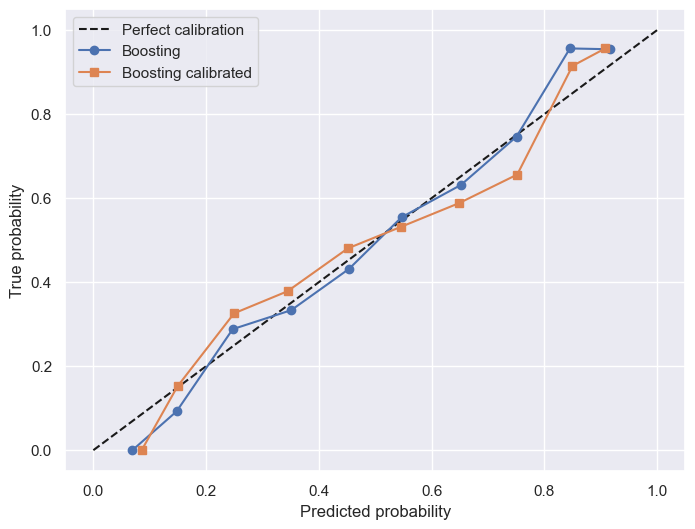

In [61]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss, brier_score_loss

calibrator = CalibratedClassifierCV(
    model_final,
    method="sigmoid",
    cv="prefit"
)

calibrator.fit(X_valid, y_valid)

probs_raw = model_final.predict_proba(X_test)[:, 1]
probs_cal = calibrator.predict_proba(X_test)[:, 1]

logloss_raw = log_loss(y_test == 1, probs_raw)
brier_raw = brier_score_loss(y_test == 1, probs_raw)

logloss_cal = log_loss(y_test == 1, probs_cal)
brier_cal = brier_score_loss(y_test == 1, probs_cal)
print(f"Boosting: LogLoss = {logloss_raw:.4f}, Brier = {brier_raw:.4f}")
print(f"Boosting calibrated: LogLoss = {logloss_cal:.4f}, Brier = {brier_cal:.4f}")

frac_raw, mean_raw = calibration_curve(y_test == 1, probs_raw, n_bins=10)
frac_cal, mean_cal = calibration_curve(y_test == 1, probs_cal, n_bins=10)

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.plot(mean_raw, frac_raw, "o-", label="Boosting")
plt.plot(mean_cal, frac_cal, "s-", label="Boosting calibrated")
plt.xlabel("Predicted probability")
plt.ylabel("True probability")
plt.legend()
plt.grid(True)
plt.show()

<font color='#b962c4'>**Вопрос:** Как вы можете прокомментировать то, что получилось?</font>

<font color='#b962c4'>**Ответ**: ... </font> Видно, что калибровка привела к небольшому ухудшению метрик LogLoss и Brier Score. Возможно калибратор переобучился на шуме валидационной выборки, пытаясь скорректировать и так достаточно точные вероятности.

## Социализационный бонус. Новогоднее 🎆 (0.5 балла)

Сфотографируйтесь с наряженной новогодней или рождественской ёлкой! Приложите фотографию, опишите свои впечатления, чего вы ждете от нового 2026 года?

жду чуда

<div>
<img src="photo_ny.jpg" width="300"/>
</div>

# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚*𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚*𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚*𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚*𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚